Dataset shape: (569, 30)

Class distribution (1 = Malignant, 0 = Benign):
malignant
0    357
1    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension
count,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000
mean,14.127,19.290,91.969,654.889,0.096,0.104,0.089,0.049,0.181,0.063
std,3.524,4.301,24.299,351.914,0.014,0.053,0.080,0.039,0.027,0.007
min,6.981,9.710,43.790,143.500,0.053,0.019,0.000,0.000,0.106,0.050
25%,11.700,16.170,75.170,420.300,0.086,0.065,0.030,0.020,0.162,0.058
50%,13.370,18.840,86.240,551.100,0.096,0.093,0.062,0.034,0.179,0.062
75%,15.780,21.800,104.100,782.700,0.105,0.130,0.131,0.074,0.196,0.066
max,28.110,39.280,188.500,2501.000,0.163,0.345,0.427,0.201,0.304,0.097


C:\Users\HP\AppData\Local\Temp\ipykernel_16976\911387794.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, ax=axes[0], palette=["steelblue", "salmon"])
C:\Users\HP\AppData\Local\Temp\ipykernel_16976\911387794.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Benign (357)", "Malignant (212)"])


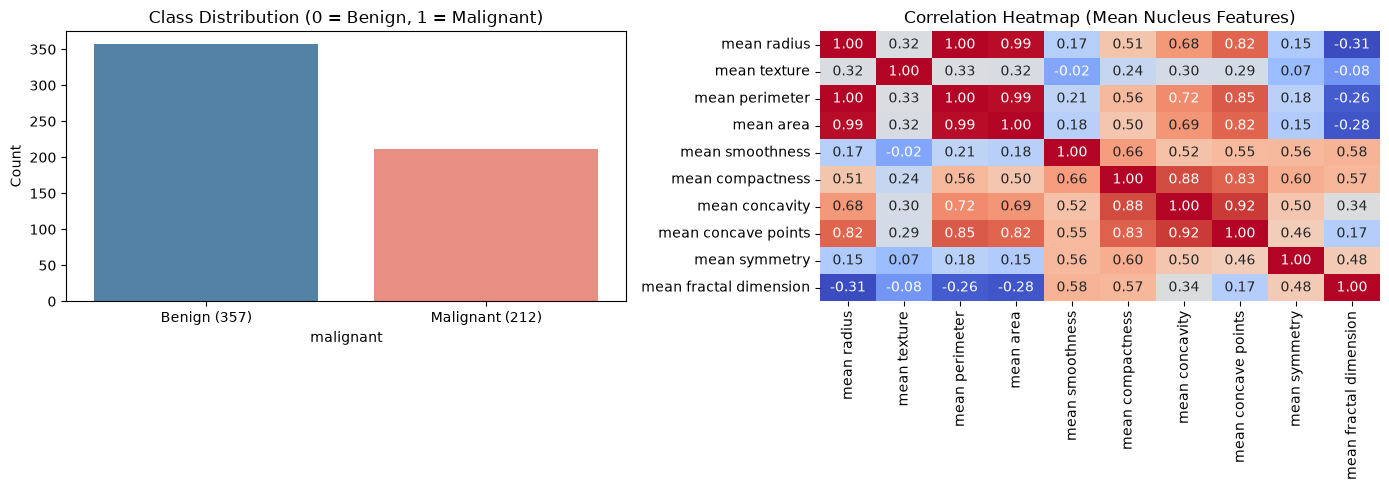


Number of feature pairs with correlation > 0.90: 21
Sample correlated pairs: [('mean perimeter', 'mean radius', np.float64(0.998)), ('mean area', 'mean radius', np.float64(0.987)), ('mean area', 'mean perimeter', np.float64(0.987)), ('mean concave points', 'mean concavity', np.float64(0.921)), ('perimeter error', 'radius error', np.float64(0.973))]


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

# Fix random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs("figures", exist_ok=True)

# Load dataset
# Note: In sklearn, 0 = malignant and 1 = benign.
# We flip it (1 - target) so 1 = Malignant (positive class) and 0 = Benign.
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(1 - data.target, name="malignant")

print(f"Dataset shape: {X.shape}")
print("\nClass distribution (1 = Malignant, 0 = Benign):")
print(y.value_counts())

# Summary statistics table (first 10 mean features)
display(X.iloc[:, :10].describe().round(3))

# Plot 1: Class distribution & Correlation heatmap
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x=y, ax=axes[0], palette=["steelblue", "salmon"])
axes[0].set_title("Class Distribution (0 = Benign, 1 = Malignant)")
axes[0].set_xticklabels(["Benign (357)", "Malignant (212)"])
axes[0].set_ylabel("Count")

corr = X.iloc[:, :10].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1], cbar=False)
axes[1].set_title("Correlation Heatmap (Mean Nucleus Features)")

plt.tight_layout()
plt.savefig("figures/a1_eda.png", dpi=300)
plt.show()

# Print highly correlated feature pairs (> 0.90)
full_corr = X.corr().abs()
upper = full_corr.where(np.triu(np.ones(full_corr.shape), k=1).astype(bool))
high_corr_pairs = [(col, row, round(upper.loc[row, col], 3)) 
                   for col in upper.columns for row in upper.index if upper.loc[row, col] > 0.90]
print(f"\nNumber of feature pairs with correlation > 0.90: {len(high_corr_pairs)}")
print("Sample correlated pairs:", high_corr_pairs[:5])

In [2]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Train size: {X_train.shape[0]} | Test size: {X_test.shape[0]}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Define 3 Pipelines (Scaler is inside Pipeline to prevent data leakage)
pipelines = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", RandomForestClassifier(random_state=RANDOM_STATE))
    ])
}

# Hyperparameter grids for 5-fold CV tuning
param_grids = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10]},
    "SVM (RBF)": {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1]},
    "Random Forest": {"clf__n_estimators": [100, 200], "clf__max_depth": [None, 5, 10]}
}

best_models = {}
cv_results = []

for name in pipelines:
    grid = GridSearchCV(
        pipelines[name], param_grids[name], cv=cv, scoring="f1", n_jobs=-1
    )
    grid.fit(X_train, y_train)
    best_models[name] = grid.best_estimator_
    
    mean_score = grid.best_score_
    std_score = grid.cv_results_["std_test_score"][grid.best_index_]
    cv_results.append({
        "Model": name,
        "Best Params": grid.best_params_,
        "CV F1 Mean": round(mean_score, 4),
        "CV F1 Std": round(std_score, 4)
    })

cv_df = pd.DataFrame(cv_results)
display(cv_df)

Train size: 455 | Test size: 114


C:\Users\HP\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Best Params,CV F1 Mean,CV F1 Std
0,Logistic Regression,{'clf__C': 1},0.9640,0.0207
1,SVM (RBF),"{'clf__C': 10, 'clf__gamma': 'scale'}",0.9674,0.0114
2,Random Forest,"{'clf__max_depth': 5, 'clf__n_estimators': 100}",0.9553,0.0284


,Model,Accuracy,Precision (Malig),Recall (Malig),F1 (Malig),ROC-AUC
0,Logistic Regression,0.9649,0.975,0.9286,0.9512,0.9960
1,SVM (RBF),0.9737,1.000,0.9286,0.9630,0.9927
2,Random Forest,0.9737,1.000,0.9286,0.9630,0.9950



Best Model on Test Set: Random Forest


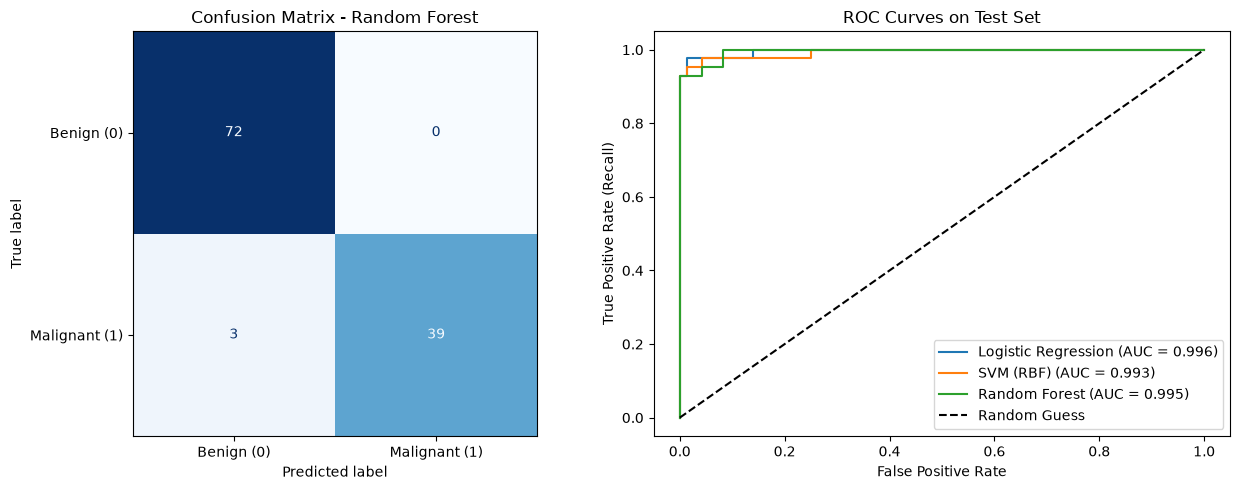

In [3]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)

test_results = []

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, model in best_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    test_results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision (Malig)": round(precision_score(y_test, y_pred), 4),
        "Recall (Malig)": round(recall_score(y_test, y_pred), 4),
        "F1 (Malig)": round(f1_score(y_test, y_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4)
    })
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, y_prob):.3f})")

results_df = pd.DataFrame(test_results)
display(results_df)

# Pick best model based on F1 / ROC-AUC (Logistic Regression or SVM usually wins)
best_model_name = results_df.sort_values(by=["F1 (Malig)", "ROC-AUC"], ascending=False).iloc[0]["Model"]
best_model = best_models[best_model_name]
print(f"\nBest Model on Test Set: {best_model_name}")

# Confusion Matrix for Best Model
cm = confusion_matrix(y_test, best_model.predict(X_test))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Benign (0)", "Malignant (1)"])
disp.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion Matrix - {best_model_name}")

# Finish ROC Plot
axes[1].plot([0, 1], [0, 1], "k--", label="Random Guess")
axes[1].set_title("ROC Curves on Test Set")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate (Recall)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/a1_results.png", dpi=300)
plt.show()